# Métodos basados en el conocimiento

## Objetivos de aprendizaje

Al finalizar este capítulo, el estudiante será capaz de:

- Comprender el fundamento del Proceso Analítico Jerárquico (AHP) como método de ponderación experta de variables.
- Construir una matriz de comparación por pares y calcular el vector de pesos mediante el vector propio (eigenvector).
- Verificar la consistencia de los juicios mediante la Razón de Consistencia (CR).
- Combinar variables raster ponderadas para producir un mapa de susceptibilidad heurístico.
- Comparar cualitativamente el resultado con mapas geomorfológicos existentes.

**Duración estimada:** 2–3 horas

## Requisitos previos

- **Python:** `numpy` (álgebra lineal: `np.linalg.eig`), `rasterio`, `matplotlib`.
- **Estadística/Álgebra:** matrices, vectores propios (eigenvectors), normalización.
- **Geotecnia:** conocimiento experto de los factores condicionantes de cada zona.
- **Capítulo anterior:** `06_variables` — las mismas variables raster se usan aquí.

Los métodos basados en el conocimiento, también denominados **heurísticos**, determinan la susceptibilidad y/o amenaza directa o indirectamente por un experto en el fenómeno y en la región de estudio. El proceso está basado en la experiencia individual y en el uso del razonamiento lógico. Las reglas de decisión son por lo tanto difíciles de formular por su complejidad y por que varían de lugar a lugar.

En estos métodos el experto puede decidir las variables y clases en que subdivide cada variable, y sobre todo el peso de las clases y el peso de las variables. De tal forma que obtiene una ecuación de susceptibilidad tal como :

$ S^n = W_1 w_c + W_2 w_c + W_3 w_c + W_n w_c $ 

donde $S^n$ es el valor de susceptibilidad de la celda n, $W_i$ es el peso de la variable i y $w_c$ es el peso de la clase a la cual pertenece la celda n en cada variable.

Los criterios utilizados generalmente por el experto son evidencia de actividad reciente, ambiente geomorfológico de cada unidad identificada, tipo de material y sus condiciones geomecánicas, pendiente de las laderas, relación con las unidades adyacentes, entre otros.

Entre las ventajas que se destacan de los métodos heurísticos está el papel dominante de la opinión del experto en el análisis, que puede ser un método utilizado en teoría a cualquier escala, sin embargo no son muy usados en escalas de detalle. También se destacan como ventaja que puede permitir una zonificación rápida incluyendo una gran cantidad de variables, y finalmente que cada poligono o unidad de análisis individual puede ser evaluado separadamente de acuerdo con su conjunto de condiciones únicas.

Como desventajas de estos métodos se señala que es una metodología subjetiva, ya que depende de la habilidad y experiencia del experto. Que sea subjetiva no es realmente una desventaja, el problema radica en la replicabilidad del método. Los análisis no se pueden generalizar y son propios en cada región. Esto mas que una desventaja es una realidad. Finalmente, se destaca que los resultados de estas metodologías son cualitativas, aunque algunas de estas metodologías utilicen valoración cuantitativa estos valores son asignados subjetivamente.

## Tipos de análisis heurísticos
Existen diferentes tipos de análisis heuristicos en cartografía geotécnica que se agrupan en métodos de mapeo directos, los cuales asignan el valor de susceptibilidad directamente en campo, y mapeo indirectos, que asignan dicho valor a las clases y/o variables y posteriormente se calcula la suscpetibilidad.
* Análisis geomorfológico (directo)
* Análisis basado en índices (indirecto)
* Análisis de decisión multicriterio (indirecto)

### Análisis geomorfológico
Estos mapas corresponden a mapas geomorfológicos de procedimiento específico denominados mapas geomorfológicos pragmáticos ({cite:t}`zuidam1985`). En la construcción de estos mapas se debe realizar un análisis de terrenos donde inicialmente se reconocen varios atributos del terreno y se clasifican en unidades, subunidades y nivel de detalle de acuerdo con la escala del estudio. Los atributos utilizados en este último nivel de detalle deben ser importantes para el alcance de la amenaza, en este caso atributos como la pendiente, el relieve, entre otros puede ser fundamental. Finalmente los terrenos clasificados deben ser evaluados en términos de susceptibilidad y/o amenaza de acuerdo con el análisis realizado.

:::{figure-md} heuristico
<img src="https://i.pinimg.com/564x/13/fe/7a/13fe7a7bf9425506078151f5289e30c5.jpg" alt="heuristico" width="800px">

Mapa geomorfológico de amenaza. Tomado de Barredo et al. (2000)
:::

Dentro de esta categoría se pueden incluir los mapas de zonificación geológico-geotécnica ampliamente utilizada en la década de los 90 en nuestra región. Entre estos se destaca la clasificación propuesta por el prof. {cite:t}`chica1989` donde define las siguiente zonas:
* **Subzonas tipo A** – Estable independiente: su estabilidad es de alto grado pues sus condiciones naturales son favorables. Posiblemente llegaría a depender del manejo mismo que se le dé al terreno.
* **Subzonas tipo B** – Estable dependiente: su estabilidad depende de factores externos, los cuales se deben corregir. También de factores internos que implican un manejo determinado del terreno y cierto tipo de obras civiles que garanticen el no deterioro de esta estabilidad natural inicial.
* **Subzonas tipo C** – Inestable recuperable: la estabilidad de estos terrenos es crítica o presenta inestabilidad manifiesta; sin embargo, con algunos correctivos específicos se puede mejorar la estabilidad, y en consecuencia, adelantar ciertas obras civiles en su interior.
* **Subzonas tipo D** – Inestable no recuperable: terrenos con inestabilidad manifiesta cuya recuperación no es posible o demasiado costosa comparada con las inversiones y tipo de obras proyectadas.
* **Subzonas tipo E** – Estable no utilizable: terrenos estables pero restringidos por condiciones urbanísticas u otras como estar ubicadas en vegas potenciales de inundación o cerca de frentes libres de taludes desprotegidos.
* **Subzonas tipo F** – Inestables no utilizables: terrenos inestables y restringidos por condiciones como las mencionadas para la subzona anterior.

:::{figure-md} heuristico1
<img src="https://i.pinimg.com/564x/ff/73/f8/ff73f874175d5e7d9b87c54a53966d0b.jpg" alt="heuristico1" width="600px">

Zonificación geológico-geotécnica del municipio de Yumbo (Valle). Tomado de Martínez et al. (1998)
:::

Existen otras propuestas como las de {cite:t}`aristizabal2011`: 

:::{figure-md} heuristico2
<img src="https://i.pinimg.com/564x/ac/c2/f3/acc2f3dacb933269f3505daf33941103.jpg" alt="heuristico2" width="600px">

Zonificación para la aptitud geotécnica del suelo propuesta por {cite:t}`aristizabal2011`.
:::

La validez de estas zonificaciones heurísticas ha sido puesta a prueba en Colombia comparándolas directamente contra modelos estadísticos sobre el mismo territorio. En el municipio de Santa Bárbara (Antioquia), González (2015) comparó un mapa heurístico con un modelo estadístico univariado a escala 1:25.000, encontrando que la subjetividad en la asignación de pesos del método heurístico llevó a una sobreestimación considerable de las zonas de alta susceptibilidad, clasificando el 52,49% del municipio como amenaza alta, frente a un 30,99% obtenido con el modelo estadístico, el cual generó una zonificación más ajustada y concentrada espacialmente alrededor de los movimientos históricos. De forma similar, en Río Tapias (Cauca), Ramírez (2017) comparó un mapa heurístico con el método bivariado de Pesos de Evidencia (WoE), encontrando nuevamente que el mapa heurístico resultó más conservador, clasificando cerca del 40% del territorio como zona de alta susceptibilidad. Estos casos evidencian una tendencia sistemática de los métodos heurísticos a sobreestimar las áreas críticas cuando no se calibran iterativamente contra el inventario histórico de movimientos en masa.

### Análisis basado en índices
Los mapas basados en índices combinan mapas de factores asociados con la ocurrencia de movimientos en masa. Los pesos son determinados para cada factor basado en un estimativo de la influencia relativa de los movimientos en masa. Las variables son generalmente divididas en clases, los cuales son ponderados utilizando el criterio de expertos. Finalmente un índice de susceptibilidad es obtenido para cada unidad.

El método más utilizado generalmente es un promedio de las clases a la que pertenece cada celda ponderado por el peso de cada variable.

:::{figure-md} heuristico-index
<img src="https://www.researchgate.net/profile/Lindsay-Ross-5/publication/229909627/figure/fig1/AS:271775443451907@1441807724040/Example-of-the-weighted-linear-combination-method-redrawn-from-Barredo-1996.png" alt="heuristico index" width="500px">

Ejemplo de combinación lineal ponderada. Tomado de Pérez et al. (2005).
:::

### Análisis de decisión multicriterio
Se define como el conjunto de aproximaciones, métodos, modelos, técnicas y herramientas dirigidas a mejorar la calidad integral de los procesos de decisión seguidos por los individuos y los sistemas, para mejorar la efectividad, eficacia y eficiencia de los procesos de decisión y a incrementar el conocimiento de los mismos. Se basa en el paradigma de la Racionalidad como una aproximación orientada al proceso, cuyo propósito es la comprensión y el consenso. Y pretende la incorporación a los modelos de aspectos subjetivos, intangibles y no considerados, que condicionan la toma de decisiones de los individuos y organizaciones (Moreno, 2000).

Probablemente el método mas utilizado para movimientos en masa de este tipo se denomina *Análisis Jerárquico de Procesos* (AHP por sus siglas en inglés). Fue desarrollado por Saaty en la década de los 60. El AHP utiliza comparaciones entre pares de elementos, construyendo una matriz a partir de estas comparaciones, que mide el juicio del tomador de decisiones de la importancia concerniente a cada criterio, agregando homogeneidad y cierto grado de certeza. Es una técnica multi-objetivo y multi-criteria para toma de decisiones que permite al usuario llegar a una escala de preferencias a partir de un determinado número de alternativas. Consiste en organizar una serie de factores en orden de jerarquía, asignando valores numéricos a valoraciones subjetivas sobre la relativa importancia de cada factor. Los pesos son obtenidos generalmente a través de los valores y vectores propios de la matriz. El vector propio que corresponde al mayor valor propio genera la prioridad relativa de los factores. También puede ser obtenido normalizando cada columna de la matriz de comparación, y calculando el promedio de las filas para resolver la matriz.

La escala utilizada en las comparaciones fue diseñada por Saaty. Esta escala incorporar los juicios o valoraciones del decisor. La escala es estrictamente positiva y elimina las ambigüedades que tiene el ser humano en comparar elementos en la proximidad del cero o del infinito. Los individuos son más precisos al comparar elementos de la misma magnitud, número mágico de Miller --> 7(+/-2).

:::{figure-md} AHP
<img src="https://www.redalyc.org/journal/104/10461231005/10461231005_gt3.png" alt="AHP" width="600px">

Escala de Saaty.
:::

Para evaluar la consistencia del análisis se estima el Radio de Consistencia (CR) de la siguiente forma:

$CR=\frac{CI}{ICA}$

Donde el CI es el Índice de Consistencia del análisis evaluado de la siguiente forma:

$\frac{\lambda_{max}-n}{n-1}$

Donde $\lambda_{max}$ es el valor propio máximo de la matriz, $n$ es el orden de la matriz. y el ICA se refiere al índice de consistencia aleatorio que se obtiene de la siguiente tabla de acuerdo con el $n$:

:::{figure-md} AHP1
<img src="https://www.researchgate.net/profile/Luciano-Franca/publication/342899316/figure/tbl1/AS:912867821891586@1594656057440/RI-Random-Index-values-for-matrices-of-different-sizes-SAATY-2005-Tabela-2-Valores.png" alt="AHP1" width="600px">

Índice de consistencia aleatoria.
:::

El Radio de Consistencia debe ser <0.1

:::{figure-md} AHP2
<img src="https://i.pinimg.com/564x/c9/4d/dd/c94ddd0de53c695374c906b97b9f948c.jpg" alt="AHP2" width="600px">

Ejemplo de la aplicación del método de AHP para movimientos en masa tomado de {cite:t}`ayalew2004`.
:::

En algunos casos se combinan los métodos, es decir con un método se pueden asignar pesos a las clases, y con otro método peso a las variables. Un ejemplo se presenta en la siguiente figura donde AHP se utiliza para asignar pesos a las variables y el método de asignación directa es utilizada para asignar pesos a las clases:

:::{figure-md} AHP-combinacion
<img src="https://i.pinimg.com/564x/cb/0c/c4/cb0cc4765fee56a8916170fda9a75adc.jpg" alt="AHP2" width="500px">

Ejemplo de combinación de métodos.
:::

Un ejemplo detallado de aplicación numérica del método AHP corresponde al estudio de la vía Puyo-Tena, en la Amazonía ecuatoriana, donde se evaluó la susceptibilidad a lo largo de 80 km de carretera con una resolución espacial de 12,5 m. Los pesos globales obtenidos mediante comparación por pares para las seis variables predisponentes, con una razón de consistencia final de 0,0039, fueron: pendiente (0,281, la de mayor influencia), formaciones geológicas (0,219), distancia a ríos (0,187), cobertura y uso del suelo (0,157), distancia a vías (0,094) y distancia a fallas (0,063, la de menor influencia). Para mitigar la subjetividad inherente a la clasificación de las clases dentro de cada variable, el Servicio Geológico Colombiano (SGC) recomienda para estudios básicos a escala rural (1:25.000) un método híbrido que combina el AHP con el método estadístico de Pesos de Evidencia (WoE): el mapa estadístico se corrige heurísticamente a partir de fotografías aéreas y validación de campo, ajustando manualmente a amenaza alta aquellas zonas que muestran indicadores geomorfológicos activos (como reptación del suelo o grietas de tensión) pero que el modelo estadístico clasificó como amenaza baja o media. Como buena práctica adicional, debe aplicarse una restricción física de área plana, fijando manualmente en el SIG una susceptibilidad nula en las celdas con pendiente de 0°, ya que en terrenos completamente planos variables no topográficas (como la geología o la lluvia) pueden generar valores de susceptibilidad artificiales.

## Python

### AHP

A continuación se describe el procedimiento para implementar el método de AHP con *Python*. El ejercicio parte con la matriz de comparación de la [Figura del ejemplo de Ayalew and Yamagishi](AHP2), denominada A. Para definir los pesos de las variables con el método AHP, se puede utilizar la función *linalg.eig* que obtiene los valores y vectores propios. Es importante tener en cuenta que los vectores propios generados por *Python* están normalizados euclidianamente, por lo tanto hay que normalizarlos a la unidad (1) con la función norm.

In [ ]:
import numpy as np

A=([[1, 0.33,  0.33,  1, 0.33, 0.33],
    [3,    1,  0.33,  5,    1,    1],
    [3,    3,     1,  3,    1,    1],
    [1,  0.2,  0.33,  1,    1,  0.2],
    [3,    1,     1,  1,    1, 0.33],
    [3,    1,     1,  5,    3,    1]])

B=np.array(A) # para transformarla en una matriz

values, vectores=np.linalg.eig(B) # Función para calcular los valores y vectores propios

vector_norm=vectores/np.linalg.norm(vectores, ord=1) # normalización de los vectores

print('esto son los valores propios',values)

esto son los valores propios [ 6.45135611+0.j         -0.0241081 +1.64871645j -0.0241081 -1.64871645j
 -0.13454859+0.43520127j -0.13454859-0.43520127j -0.13404274+0.j        ]


In [ ]:
print('esto son los vectores propios', vectores)

esto son los vectores propios /n [[ 0.14436866+0.j          0.02398294+0.00827384j  0.02398294-0.00827384j
   0.20536727+0.14878211j  0.20536727-0.14878211j  0.14221686+0.j        ]
 [ 0.42599629+0.j          0.01147632+0.48741276j  0.01147632-0.48741276j
   0.1945605 -0.27358166j  0.1945605 +0.27358166j  0.0758326 +0.j        ]
 [ 0.56812531+0.j          0.66446338+0.j          0.66446338-0.j
  -0.78171181+0.j         -0.78171181-0.j         -0.71758058+0.j        ]
 [ 0.1578558 +0.j         -0.15986003-0.05675779j -0.15986003+0.05675779j
  -0.07345944-0.04273917j -0.07345944+0.04273917j -0.21773253+0.j        ]
 [ 0.32625087+0.j          0.09149542-0.33367399j  0.09149542+0.33367399j
   0.16766496-0.13753574j  0.16766496+0.13753574j  0.2047162 +0.j        ]
 [ 0.58614025+0.j         -0.39877545+0.11239927j -0.39877545-0.11239927j
  -0.26017993+0.29994993j -0.26017993-0.29994993j  0.60810009+0.j        ]]


In [ ]:
print('esto son los vectores propios normalizados',vector_norm)

esto son los vectores propios normalizados [[ 0.06536254+0.j          0.01085821+0.00374596j  0.01085821-0.00374596j
   0.0929795 +0.06736071j  0.0929795 -0.06736071j  0.06438831+0.j        ]
 [ 0.19286871+0.j          0.00519587+0.22067486j  0.00519587-0.22067486j
   0.08808676-0.12386338j  0.08808676+0.12386338j  0.03433301+0.j        ]
 [ 0.25721725+0.j          0.30083406+0.j          0.30083406-0.j
  -0.35391798+0.j         -0.35391798+0.j         -0.32488273+0.j        ]
 [ 0.0714688 +0.j         -0.07237621-0.02569694j -0.07237621+0.02569694j
  -0.03325857-0.01935005j -0.03325857+0.01935005j -0.09857784+0.j        ]
 [ 0.14770923+0.j          0.04142431-0.15107003j  0.04142431+0.15107003j
   0.07590987-0.06226895j  0.07590987+0.06226895j  0.09268472+0.j        ]
 [ 0.26537347+0.j         -0.18054454+0.05088847j -0.18054454-0.05088847j
  -0.11779579+0.13580155j -0.11779579-0.13580155j  0.27531573+0.j        ]]


Los anteriores valores corresponden a los valores propios de la matriz. Se obtiene entonces el vector propio del mayor valor propio, en ese caso corresponde al primer valor propio.

In [ ]:
w=vector_norm[:,0]
print(w)

[0.06536254+0.j 0.19286871+0.j 0.25721725+0.j 0.0714688 +0.j
 0.14770923+0.j 0.26537347+0.j]


Estos valores significan que la primera variable *Aspect* tiene un peso del 6%, la segunda variable *Elevation* del 19%, la tercera variable *Lithology* del 25%, la cuarta variable *Plan curvature* del 7%, la quinta variable *Profile curvature* del 14%, y la sexta variable *Slope gradient* del 26%.

Para calcular la consistencia del análisis se procede entonces a calcular el indice de consistencia, con $\lambda_{max}$ que representa el valor propio máximo, n que corresponde a la longitud de la matrix, y el índice de consistencia aleatorio que se obtiene de la tabla en la [Figura](AHP1).

In [ ]:
CI=(values[0]-len(values))/(len(values)-1)

CR= CI/1.24

print(CR)

(0.07279937283948756+0j)


Se obtiene un radio de consistencia $0.07<0.1$ por lo tanto el análisis esta OK.

### Método combinado

En este caso se evaluará la susceptibilidad por movimientos en masa en la cuenca de la quebrada La Miel en el municipio de Caldas (Antioquia). Se utilizará el ejemplo anterior, donde se asignaron pesos a las clases, y se combinará con asignación directa de pesos a las clases que conforman cada variable. 

Se procede entonces a importar cada uno de los mapas a utilizar. En este caso 6 mapas de las variables predictoras que se utilizaron en el método AHP.

In [ ]:
!pip install rasterio

In [ ]:
import rasterio as rio
import matplotlib.pyplot as plt
import numpy as np

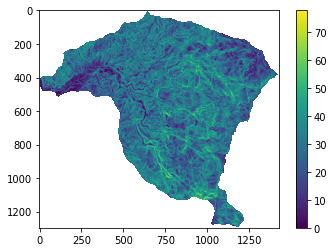

In [ ]:
raster = rio.open('https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/Pendiente.tif')
pendiente=raster.read(1)
pendiente=np.where(pendiente<0,np.nan,pendiente)
plt.imshow(pendiente);
plt.colorbar();

De acuerdo con el método estos mapas se deben reclasificar en clases y pesos con criterio de experto. Se recomienda utilizar los rangos recomendados por el SGC o por referencias conocidas. Este ejercicio simplemente señala el procedimiento, pero no tiene ningún análisis o criterio la reclasificación utilizada. Para este caso se utilizarán valores a las clases en un rango de 0 a 1. Donde 0 significa baja incidencia en la ocurrencia de movimientos en masa y 1 significa muy alta. 

El procedimiento entonces corresponde a reclasificar en clases cada mapa y asignar un valor entre 0 a 1 a clada clase.

[0.1 0.5 1.  nan]


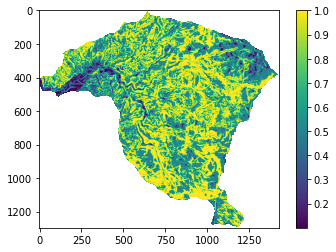

In [ ]:
pendiente_re=np.where ( (np.logical_and (pendiente>=0, pendiente<10 )),0.1,pendiente );
pendiente_re=np.where ( (np.logical_and (pendiente_re>=10, pendiente_re<30 )),0.5,pendiente_re);
pendiente_re=np.where ( pendiente_re>=30,1,pendiente_re);
print(np.unique(pendiente_re));
plt.imshow(pendiente_re);
plt.colorbar();

[ 2.  4.  6.  8.  9. 10. 11. 14. 15. 16. nan]


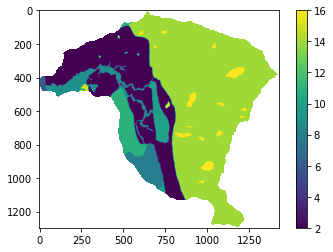

In [ ]:
raster = rio.open('https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/Geologia_Superficial.tif')
geologia=raster.read(1)
geologia=np.where(geologia<0,np.nan,geologia)
print(np.unique(geologia));
plt.imshow(geologia);
plt.colorbar();

[0.1 0.2 0.4 1.  nan]


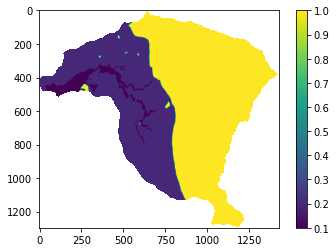

In [ ]:
geologia_re=np.where ( geologia>=14,1,geologia)
geologia_re=np.where ( geologia_re==9,0.1,geologia_re)
geologia_re=np.where ( geologia_re==4,0.4,geologia_re)
geologia_re=np.where ( geologia_re>=2,0.2,geologia_re)
print(np.unique(geologia_re))
plt.imshow(geologia_re);
plt.colorbar();

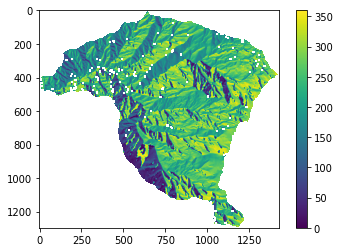

In [ ]:
raster = rio.open(r'https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/Aspecto.tif')
aspecto=raster.read(1)
aspecto=np.where(aspecto<0,np.nan,aspecto)
plt.imshow(aspecto);
plt.colorbar();

[0.1 0.2 0.5 0.9 nan]


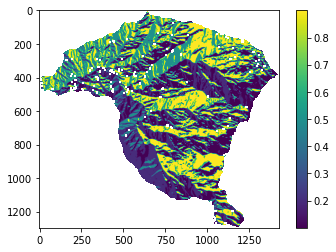

In [ ]:
aspecto_re=np.where ( aspecto<90,0.2,aspecto);
aspecto_re=np.where ( (np.logical_and (aspecto_re>=90, aspecto_re<180 )),0.5,aspecto_re);
aspecto_re=np.where ( (np.logical_and (aspecto_re>=180, aspecto_re<270 )),0.9,aspecto_re);
aspecto_re=np.where ( aspecto_re>=270,0.1,aspecto_re);
print(np.unique(aspecto_re))
plt.imshow(aspecto_re);
plt.colorbar();

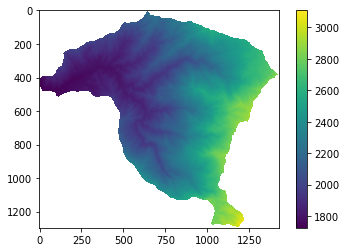

In [ ]:
raster = rio.open('https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/DEM5m.tif')
elevacion=raster.read(1)
elevacion=np.where(elevacion<0,np.nan,elevacion)
plt.imshow(elevacion);
plt.colorbar();

[0.1 0.2 0.5 0.9 nan]


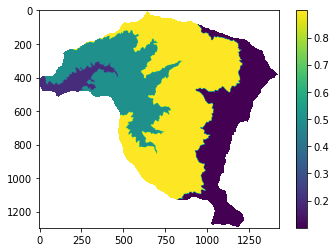

In [ ]:
elevacion_re=np.where ( elevacion<1800,0.2,elevacion);
elevacion_re=np.where ( (np.logical_and (elevacion_re>=1800, elevacion_re<2000 )),0.5,elevacion_re);
elevacion_re=np.where ( (np.logical_and (elevacion_re>=2000, elevacion_re<2500 )),0.9,elevacion_re);
elevacion_re=np.where ( elevacion_re>=2500,0.1,elevacion_re);
print(np.unique(elevacion_re))
plt.imshow(elevacion_re);
plt.colorbar();

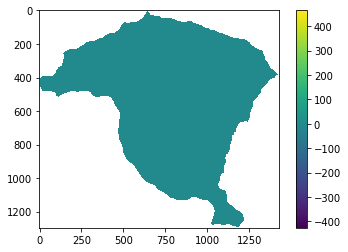

In [ ]:
raster = rio.open('https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/CurvaturaPerfil.tif')
curvaturaV=raster.read(1)
curvaturaV=np.where(curvaturaV==-999.0,np.nan,curvaturaV) # en este caso no se puede utilizar <0 por que hay valores de curvatura que son negativos
plt.imshow(curvaturaV);
plt.colorbar();

[0.1 0.3 0.9 nan]


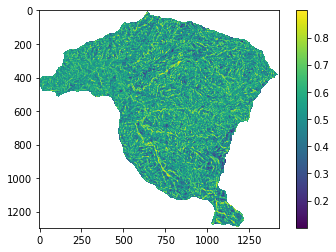

In [ ]:
curvaturaV_re=np.where ( curvaturaV>=0.005,0.9,curvaturaV);
curvaturaV_re=np.where ( (np.logical_and (curvaturaV_re>=-0.5, curvaturaV_re<0.5 )),0.1,curvaturaV_re);
curvaturaV_re=np.where ( curvaturaV_re<-0.005,0.3,curvaturaV_re);
print(np.unique(curvaturaV_re))
plt.imshow(curvaturaV_re);
plt.colorbar();

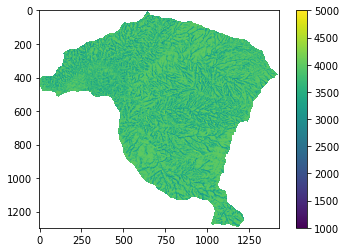

In [ ]:
raster = rio.open('https://raw.githubusercontent.com/edieraristizabal/CartografiaGeotecnica/master/libro/data/CurvaturaPlana.tif')
curvaturaH=raster.read(1)
curvaturaH=np.where(curvaturaH==-999.0,np.nan,curvaturaH) # en este caso no se puede utilizar <0 por que hay valores de curvatura que son negativos
plt.imshow(curvaturaH);
plt.colorbar();

[0.1 0.9 nan]


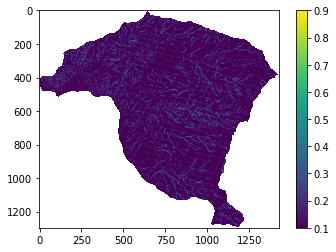

In [ ]:
curvaturaH_re=np.where ( curvaturaH<=2000,0.9,curvaturaH);
curvaturaH_re=np.where ( (np.logical_and (curvaturaH_re>=2000, curvaturaH_re<=3000 )),0.1,curvaturaH_re);
curvaturaH_re=np.where ( curvaturaH_re>3000,0.1,curvaturaH_re);
print(np.unique(curvaturaH_re))
plt.imshow(curvaturaH_re);
plt.colorbar();

In [ ]:
print(w[0],w[1],w[2],w[3],w[4],w[5])

(0.06536253617532849+0j) (0.1928687090376127+0j) (0.2572172528769481+0j) (0.07146880296600812+0j) (0.14770923077095524+0j) (0.2653734681731474+0j)


Finalmente se aplica la ecuación de IS y se obtiene el mapa.

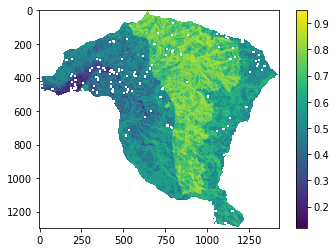

In [ ]:
IS=0.065*aspecto_re+0.192*elevacion_re+0.257*geologia_re+0.071*curvaturaH_re+0.147*curvaturaV_re+0.265*pendiente_re
plt.imshow(IS);
plt.colorbar();

Para exportar el mapa como archivo tiff y poder trabajar en un GIS, se puede utilizar la librería rasterio, y sustraer los datos de georreferenciación y tamaño del mapa de aspecto en ese caso.

In [ ]:
meta=raster.profile
raster_transform = meta['transform']
raster_crs = meta['crs']

with rio.open('IS.TIF', 'w', 
              driver='Gtiff',height=aspecto.shape[0],width=aspecto.shape[1],count=1,
              dtype='float64',nodata=-999,crs=raster_crs,transform=raster_transform) as dst:
    dst.write(IS,1);

## Actividades

1. **Cambio de pesos AHP:** Modifica la matriz de comparación por pares asignando mayor importancia a la geología respecto a la pendiente. Recalcula los pesos y el mapa de susceptibilidad resultante. ¿Cuánto cambia el área clasificada como alta susceptibilidad?

2. **Verificación de consistencia:** Implementa el cálculo de la Razón de Consistencia (CR = CI/RI) para tu nueva matriz. Si CR > 0.1, ajusta los juicios hasta lograr una matriz consistente. ¿Cuántas iteraciones necesitaste?

3. **Validación cruzada con inventario:** Superpone el mapa de susceptibilidad AHP con el inventario de movimientos en masa y calcula qué porcentaje de los movimientos cae en zonas de susceptibilidad alta o muy alta. Compara este valor con los métodos estadísticos del capítulo 09.

4. **Limitaciones del método:** Discute en máximo 300 palabras las principales limitaciones del AHP para cartografía geotécnica. ¿Por qué se considera un método subjetivo y cuándo está justificado su uso?

## Referencias
```{bibliography}
:style: plain
:filter: docname in docnames
```